# NV-diamond qubits: a room-temperature magnetometer and the "qubit wheel"

An NV center (a nitrogen atom next to a missing carbon in diamond) is a spin qubit that
works **at room temperature** and **measures magnetic fields**. This notebook ties together
everything built this session:

| Piece | From | Used here for |
|---|---|---|
| Energy diagrams, Zeeman levels | PHYS 106 / Knight Ch. 40 | the m_s = 0, ±1 levels vs B |
| Boltzmann factor | `cryo_qubit_readout.ipynb` | why the NV needs a laser, not a fridge |
| Lorentzian resonance, Q | EEE 117 | ODMR dips and linewidth |
| Rabi oscillation, π pulse = NOT | `knight_ch40_one_d_quantum.ipynb` | the Bloch-sphere "qubit wheel" |
| Eyewear OD | `laser_eyewear_od.ipynb` | the 532 nm pump laser |

Module: `dgs/nv_diamond.py` (tests: `tests/test_nv_diamond.py`). Device numbers marked
*illustrative* are typical orders of magnitude, not a specific sample.

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, HTML

from dgs import nv_diamond as N, cryo_readout as R, laser_eyewear as S
pd.set_option("display.width", 200)
print(f"D = {N.D_HZ / 1e9:.3f} GHz,  gamma = {N.GAMMA_HZ_T / 1e9:.3f} GHz/T = {N.GAMMA_HZ_T * 1e-4 / 1e6:.3f} MHz/G")

D = 2.870 GHz,  gamma = 28.034 GHz/T = 2.803 MHz/G


## 1. Why no dilution refrigerator? Boltzmann vs optical pumping

The transmon in `cryo_qubit_readout.ipynb` had to be cooled until k_BT ≪ hf. For the NV,
hf = h·2.87 GHz while k_BT at 300 K is about h·6 THz. Thermally, the three levels are almost
equally filled. The NV is **optically pumped** instead: green light cycles it through an
excited state, and a spin-dependent decay path funnels population into m_s = 0. That decay path
also makes m_s = ±1 glow about 30% dimmer. The same mechanism gives both initialization and
readout.

In [2]:
kT_over_h = R.K_B * 300 / R.H
pops = R.level_populations(N.D_HZ, 300.0, n_levels=2)
print(f"k_B T / h at 300 K = {kT_over_h / 1e12:.2f} THz  vs  D = {N.D_HZ / 1e9:.2f} GHz  (ratio {kT_over_h / N.D_HZ:.0f})")
print(f"thermal P(upper)/P(lower) at 300 K = {pops[1] / pops[0]:.5f}  -> essentially unpolarized")
print(f"temperature needed for P(upper) = 1e-3 at 2.87 GHz: {R.effective_temperature(N.D_HZ, 1e-3) * 1e3:.0f} mK")
print("optical pumping typically reaches m_s = 0 populations of order 80-90% at room temperature (illustrative).")

k_B T / h at 300 K = 6.25 THz  vs  D = 2.87 GHz  (ratio 2178)
thermal P(upper)/P(lower) at 300 K = 0.99954  -> essentially unpolarized
temperature needed for P(upper) = 1e-3 at 2.87 GHz: 20 mK
optical pumping typically reaches m_s = 0 populations of order 80-90% at room temperature (illustrative).


## 2. PHYS 106: the energy diagram (spin-1 Zeeman effect)

**Quantity:** the energy levels of the NV ground state. **Equation:**
H/h = D S_z² + γB S_z for a field along the NV axis. **Isolated:** H is diagonal, so the
levels are 0 and D ± γB. **Units:** D in Hz, γ in Hz/T, B in T. **Meaning:** the two
microwave transitions split apart linearly in B. Measuring their gap measures B.

      ⎡B⋅γ + D  0     0    ⎤
      ⎢                    ⎥
H/h = ⎢   0     0     0    ⎥
      ⎢                    ⎥
      ⎣   0     0  -B⋅γ + D⎦

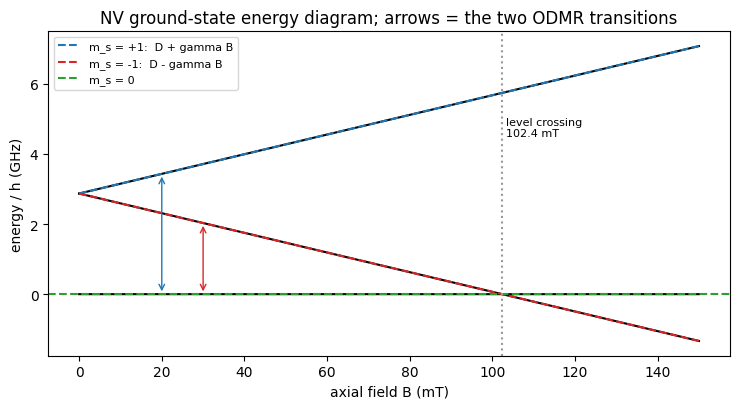

In [3]:
Dz, g, B = sp.symbols("D gamma B", positive=True)
Sz = sp.diag(1, 0, -1)
Hs = Dz * Sz**2 + g * B * Sz
display(sp.Eq(sp.Symbol("H/h"), Hs, evaluate=False))
display(Hs.eigenvals())
fp, fm = Dz + g * B, Dz - g * B
display(sp.Eq(sp.Symbol("B"), sp.solve(sp.Eq(sp.Symbol("f_+") - sp.Symbol("f_-"), fp - fm), B)[0]))

Bs = np.linspace(0, 0.15, 400)
lv = np.array([np.sort(N.levels([0, 0, b])[0]) for b in Bs])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, lab in enumerate(["", "", ""]):
    ax.plot(Bs * 1e3, lv[:, k] / 1e9, "k")
ax.plot(Bs * 1e3, (N.D_HZ + N.GAMMA_HZ_T * Bs) / 1e9, "C0--", label="m_s = +1:  D + gamma B")
ax.plot(Bs * 1e3, (N.D_HZ - N.GAMMA_HZ_T * Bs) / 1e9, "C3--", label="m_s = -1:  D - gamma B")
ax.axhline(0, color="C2", ls="--", label="m_s = 0")
Bglac = N.D_HZ / N.GAMMA_HZ_T
ax.axvline(Bglac * 1e3, color="0.6", ls=":"); ax.text(Bglac * 1e3 + 1, 4.5, f"level crossing\n{Bglac * 1e3:.1f} mT", fontsize=8)
ax.annotate("", xy=(20, (N.D_HZ + N.GAMMA_HZ_T * 0.02) / 1e9), xytext=(20, 0), arrowprops=dict(arrowstyle="<->", color="C0"))
ax.annotate("", xy=(30, (N.D_HZ - N.GAMMA_HZ_T * 0.03) / 1e9), xytext=(30, 0), arrowprops=dict(arrowstyle="<->", color="C3"))
ax.set_xlabel("axial field B (mT)"); ax.set_ylabel("energy / h (GHz)"); ax.legend(fontsize=8)
ax.set_title("NV ground-state energy diagram; arrows = the two ODMR transitions")
plt.tight_layout(); plt.show()

## 3. ODMR: reading the field off fluorescence dips

Sweep the microwave frequency and watch the red fluorescence. Each transition makes a
Lorentzian dip. *Illustrative:* linewidth 1 MHz, contrast 10%.
* **Field along one NV axis:** two dips, B = (f₊ − f₋)/(2γ).
* **Field in a general direction:** each of the four ⟨111⟩ NV orientations sees a different
  projection, giving **up to 8 dips**. Their pattern encodes the field's direction: a vector
  magnetometer in one crystal.

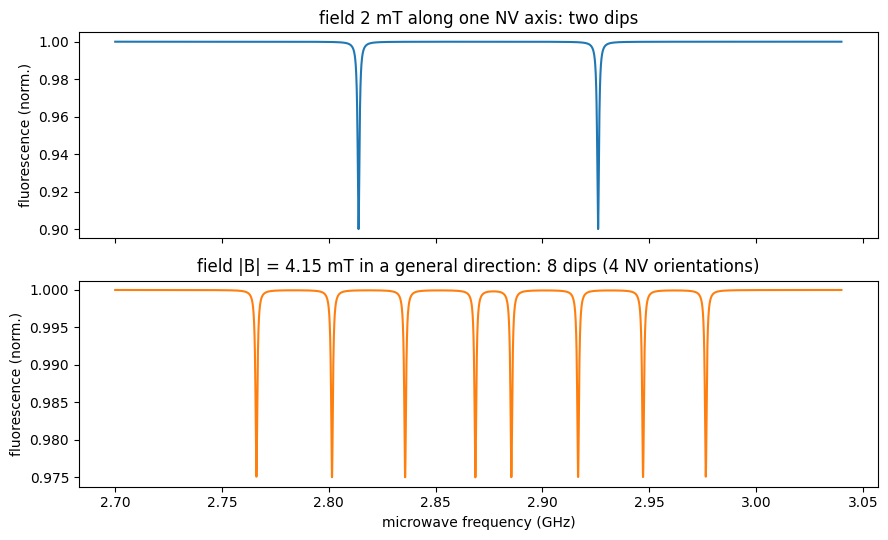

recovered axial field: 2.0000 mT (true 2.0 mT)


,NV axis,|B . axis| (mT),splitting / 2 gamma (mT)
0,[111],3.7528,3.7522
1,[1-1-1],2.5981,2.5973
2,[-11-1],1.4434,1.4442
3,[-1-11],0.2887,0.3003


small differences = second-order effect of the transverse field component


In [4]:
f = np.linspace(2.70e9, 3.04e9, 6000)
B_ax = 2e-3
lines_ax = N.odmr_frequencies([0, 0, B_ax])
B_lab = np.array([1.0, 2.0, 3.5]) * 1e-3          # illustrative lab-frame field (T)
lines_4 = N.odmr_lines_all_orientations(B_lab)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
a1.plot(f / 1e9, N.odmr_spectrum(f, lines_ax, 1e6, 0.1))
a1.set_title(f"field {B_ax * 1e3:.0f} mT along one NV axis: two dips")
a2.plot(f / 1e9, N.odmr_spectrum(f, lines_4.ravel(), 1e6, 0.1 / 4), "C1")
a2.set_title(f"field |B| = {np.linalg.norm(B_lab) * 1e3:.2f} mT in a general direction: 8 dips (4 NV orientations)")
for ax in (a1, a2): ax.set_ylabel("fluorescence (norm.)")
a2.set_xlabel("microwave frequency (GHz)"); plt.tight_layout(); plt.show()

print(f"recovered axial field: {N.field_from_splitting(*lines_ax) * 1e3:.4f} mT (true {B_ax * 1e3} mT)")
proj = [abs(B_lab @ ax_) for ax_ in N.NV_AXES]
split = [N.field_from_splitting(*l) for l in lines_4]
display(pd.DataFrame({"NV axis": ["[111]", "[1-1-1]", "[-11-1]", "[-1-11]"],
                      "|B . axis| (mT)": np.array(proj) * 1e3,
                      "splitting / 2 gamma (mT)": np.array(split) * 1e3}).round(4))
print("small differences = second-order effect of the transverse field component")

## 4. EEE 117: linewidth, Q, and sensitivity

An ODMR dip has the same Lorentzian shape as the RLC resonance near f₀, and Q = f₀/Δf.
A 1 MHz line at 2.87 GHz has Q ≈ 2900. **How small a field can you see?** You locate the dip
center to within noise. The shot-noise-limited CW sensitivity is

$$\eta \approx \frac{4}{3\sqrt3}\,\frac{\Delta f}{\gamma\, C\, \sqrt{R}} \quad [\mathrm{T}/\sqrt{\mathrm{Hz}}],$$

where Δf is the linewidth, C the contrast, and R the detected photon rate. Narrower lines,
deeper dips, and more photons all help.

In [5]:
cases = {"single NV (illustrative)": (5e6, 0.2, 1e5), "small ensemble": (1e6, 0.02, 1e10), "optimized ensemble": (0.3e6, 0.03, 1e13)}
rows = [(k, lw / 1e6, N.D_HZ / lw, C, Rr, N.cw_sensitivity(lw, C, Rr)) for k, (lw, C, Rr) in cases.items()]
df = pd.DataFrame(rows, columns=["case", "linewidth (MHz)", "Q = f0/linewidth", "contrast", "photons/s", "eta (T/sqrt Hz)"])
df["eta (nT/sqrt Hz)"] = df["eta (T/sqrt Hz)"] * 1e9
display(df.drop(columns="eta (T/sqrt Hz)").round(3))
print("Earth's field is ~50 uT; a car passing 10 m away changes it by roughly tens of nT (order of magnitude).")

,case,linewidth (MHz),Q = f0/linewidth,contrast,photons/s,eta (nT/sqrt Hz)
0,single NV (illustrative),5.0,574.000,0.20,1.000000e+05,2170.829
1,small ensemble,1.0,2870.000,0.02,1.000000e+10,13.730
2,optimized ensemble,0.3,9566.667,0.03,1.000000e+13,0.087


Earth's field is ~50 uT; a car passing 10 m away changes it by roughly tens of nT (order of magnitude).


## 5. The qubit wheel: Bloch sphere

The m_s = 0 / m_s = −1 pair is a qubit. Use north pole = |0⟩ (bright) and south pole =
|−1⟩ (dim). A microwave at detuning Δ with Rabi frequency Ω rotates the state around the axis
(Ω, 0, Δ):

* **resonant π pulse:** pole to pole along a meridian, which is the NOT gate;
* **π/2 pulse:** to the equator, an equal superposition (the first step of Ramsey magnetometry);
* **detuned drive:** a tilted cone that never reaches the south pole, so the flip is incomplete.

The tests check that P(|−1⟩) = (1 − z)/2 here equals `rabi_population` from Chapter 40 exactly.

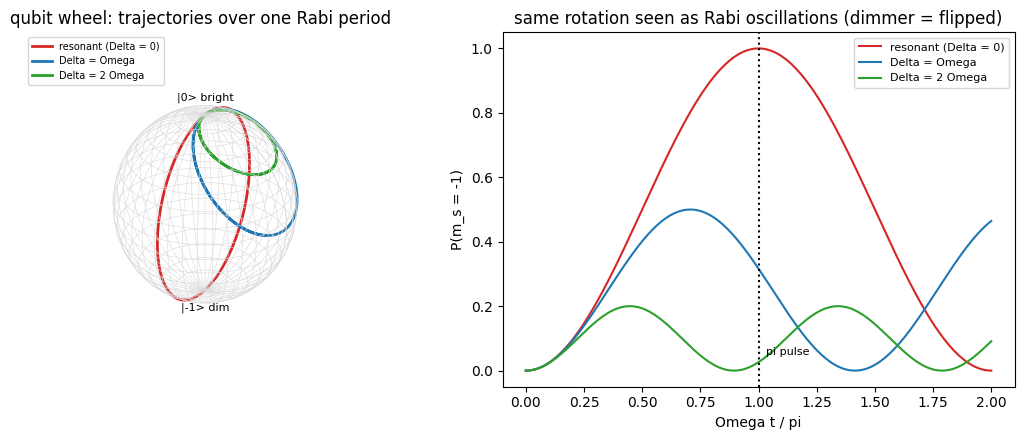

In [6]:
Om = 2 * math.pi * 10e6
t = np.linspace(0, 2 * math.pi / Om, 200)
traj = {"resonant (Delta = 0)": N.bloch_vector(Om, 0.0, t),
        "Delta = Omega": N.bloch_vector(Om, Om, t),
        "Delta = 2 Omega": N.bloch_vector(Om, 2 * Om, t)}

def sphere(ax):
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="0.85", lw=0.4)
    for vec, lab in [((0, 0, 1.15), "|0> bright"), ((0, 0, -1.25), "|-1> dim")]:
        ax.text(*vec, lab, fontsize=8, ha="center")
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()

fig = plt.figure(figsize=(11, 4.5))
ax3 = fig.add_subplot(1, 2, 1, projection="3d"); sphere(ax3)
for (lab, r), c in zip(traj.items(), ["C3", "C0", "C2"]):
    ax3.plot(r[:, 0], r[:, 1], r[:, 2], c, lw=2, label=lab)
ax3.legend(fontsize=7, loc="upper left"); ax3.set_title("qubit wheel: trajectories over one Rabi period")
ax2 = fig.add_subplot(1, 2, 2)
for (lab, r), c in zip(traj.items(), ["C3", "C0", "C2"]):
    ax2.plot(t * Om / math.pi, (1 - r[:, 2]) / 2, c, label=lab)
ax2.axvline(1, color="k", ls=":"); ax2.text(1.03, 0.05, "pi pulse", fontsize=8)
ax2.set_xlabel("Omega t / pi"); ax2.set_ylabel("P(m_s = -1)"); ax2.legend(fontsize=8)
ax2.set_title("same rotation seen as Rabi oscillations (dimmer = flipped)")
plt.tight_layout(); plt.show()

In [7]:
# Animated qubit wheel: a resonant pi pulse, then a pi/2 pulse from the north pole
plt.rcParams["animation.embed_limit"] = 30
frames = 36
r_pi = N.bloch_vector(Om, 0.0, np.linspace(0, math.pi / Om, frames))
fig = plt.figure(figsize=(4.2, 4.2), dpi=70)
ax = fig.add_subplot(projection="3d"); sphere(ax)
path, = ax.plot([], [], [], "C3", lw=2)
arrow, = ax.plot([], [], [], "k", lw=3)
title = ax.set_title("")

def draw(k):
    r = r_pi[: k + 1]
    path.set_data(r[:, 0], r[:, 1]); path.set_3d_properties(r[:, 2])
    arrow.set_data([0, r[-1, 0]], [0, r[-1, 1]]); arrow.set_3d_properties([0, r[-1, 2]])
    title.set_text(f"pulse area {180 * k / (frames - 1):.0f} deg   P(-1) = {(1 - r[-1, 2]) / 2:.2f}")
    return path, arrow, title

anim = animation.FuncAnimation(fig, draw, frames=frames, interval=80, blit=False)
html = anim.to_jshtml()
plt.close(fig)
HTML(html)

## 6. Ramsey magnetometry: a phase clock for the field

π/2 pulse, wait τ, π/2 pulse. During the wait, the superposition precesses at the detuning
δ = γ·ΔB, so the final population oscillates as cos(2π δ τ). It decays with the dephasing
time T₂*. A longer wait means more phase per tesla and a finer measurement, until T₂* washes
the fringes out. *Illustrative:* T₂* = 1 µs, δ for ΔB = 0.1 mT.

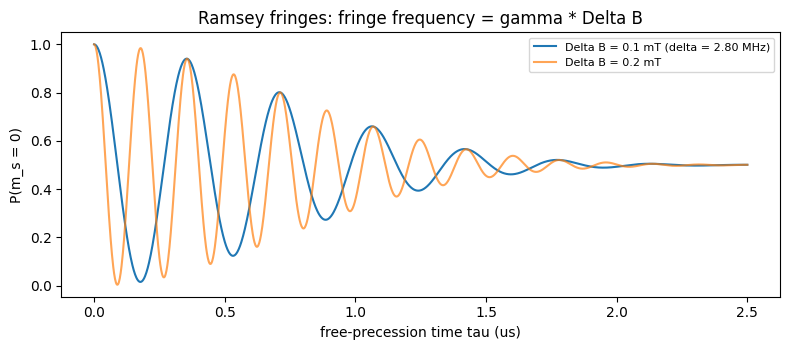

phase per microtesla per microsecond of waiting = 0.176 rad


In [8]:
dB = 1e-4
delta = N.GAMMA_HZ_T * dB
tau = np.linspace(0, 2.5e-6, 1500)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(tau * 1e6, N.ramsey_signal(tau, delta, 1e-6), label=f"Delta B = {dB * 1e3:.1f} mT (delta = {delta / 1e6:.2f} MHz)")
ax.plot(tau * 1e6, N.ramsey_signal(tau, N.GAMMA_HZ_T * 2 * dB, 1e-6), alpha=0.7, label=f"Delta B = {2 * dB * 1e3:.1f} mT")
ax.set_xlabel("free-precession time tau (us)"); ax.set_ylabel("P(m_s = 0)"); ax.legend(fontsize=8)
ax.set_title("Ramsey fringes: fringe frequency = gamma * Delta B")
plt.tight_layout(); plt.show()
print(f"phase per microtesla per microsecond of waiting = {2 * math.pi * N.GAMMA_HZ_T * 1e-6 * 1e-6:.3f} rad")

## 7. Bonus sensors and the safety tie-in

* **Thermometer:** D itself shifts with temperature (about −74 kHz/K near 300 K), so the
  same measurement senses heat.
* **The pump laser is a Class 3B / 4 hazard.** A typical lab NV setup uses a 532 nm laser at
  tens to hundreds of mW (illustrative). The eyewear calculator from `laser_eyewear_od.ipynb` applies directly.

In [9]:
for T in (290, 300, 310):
    print(f"T = {T} K: D = {N.zero_field_splitting(T) / 1e9:.6f} GHz")
P_pump, a, phi = 0.1, 0.1, 1e-3
E_eye = float(S.irradiance(P_pump, 30, a, phi))
mpe = S.mpe_visible(0.25)
print(f"\n100 mW, 532 nm pump, 1 mm beam, viewed from 30 cm: needs OD >= {S.required_od(E_eye, mpe):.2f}; "
      f"hazard distance {S.nohd(P_pump, mpe, a, phi) / 100:.0f} m")

T = 290 K: D = 2.870742 GHz
T = 300 K: D = 2.870000 GHz
T = 310 K: D = 2.869258 GHz

100 mW, 532 nm pump, 1 mm beam, viewed from 30 cm: needs OD >= 3.47; hazard distance 70 m


## Practice (my own problems)

1. ODMR lines at 2.814 GHz and 2.926 GHz with the field along the NV axis. What is B?
2. What field makes the m_s = −1 level cross m_s = 0?
3. A 2 MHz linewidth, 1% contrast, 10¹² photons/s ensemble: what is the CW sensitivity in nT/√Hz?
4. After a π/2 pulse from the north pole, where is the Bloch vector, and what is P(−1)?
5. A Ramsey fringe has a period of 0.5 µs. What field offset is that?

In [10]:
print(f"1. B = {N.field_from_splitting(2.814e9, 2.926e9) * 1e3:.3f} mT")
print(f"2. B = D / gamma = {N.D_HZ / N.GAMMA_HZ_T * 1e3:.1f} mT")
print(f"3. eta = {N.cw_sensitivity(2e6, 0.01, 1e12) * 1e9:.1f} nT/sqrt(Hz)")
r = N.bloch_vector(Om, 0, math.pi / (2 * Om))
print(f"4. r = {np.round(r, 6)} (on the equator), P(-1) = {(1 - r[2]) / 2:.2f}")
print(f"5. delta = 1/0.5 us = 2 MHz -> Delta B = {2e6 / N.GAMMA_HZ_T * 1e6:.1f} uT")

1. B = 1.998 mT
2. B = D / gamma = 102.4 mT
3. eta = 5.5 nT/sqrt(Hz)
4. r = [ 0. -1.  0.] (on the equator), P(-1) = 0.50
5. delta = 1/0.5 us = 2 MHz -> Delta B = 71.3 uT


## Checklist

- [ ] NV levels on axis: 0 and D ± γB, with D = 2.87 GHz and γ = 28.03 GHz/T. B = (f₊ − f₋)/(2γ).
- [ ] Four ⟨111⟩ orientations give up to 8 ODMR lines, which encode the field's direction.
- [ ] Room temperature works because the NV is optically pumped, not cooled: k_BT/h ≈ 6 THz ≫ 2.87 GHz.
- [ ] Lorentzian dip: Q = f₀/Δf. Sensitivity ∝ Δf/(C√R).
- [ ] Bloch sphere: a π pulse goes pole to pole (NOT), a π/2 pulse goes to the equator. Detuning tilts the axis, so the flip is incomplete.
- [ ] Ramsey: phase = 2πγΔBτ, limited by T₂*.
- [ ] The 532 nm pump laser needs eyewear: compute the OD.